# Final evaluation and error analysis

**Group 07 · completed presentation studies · reviewed 14 October 2026**

Compare Phase 1 standard/weighted BERT with the retained Phase 2 mixture on
five matched seeds and identical eligible reference answers. Explain prediction
transitions, LODO category coverage, rarity and NULL.

**Main result:** explicit test F1 **33.41% → 40.28% (+6.88 percentage points)**.
The newer NULL adaptation did not improve joint extraction.

This notebook does **not** train models, download BERT or tune thresholds on
test data. It needs no GPU. The ongoing optional class-balanced study is separate.

Long code lives in [notebook_analysis.py](../notebook_analysis.py).
See the [Phase 2 README](../README.md) for the short reviewer guide and
[untouched original notebook](../reference/notebooks/Final_Evaluation_and_Error_Analysis_original.ipynb).

## 1. Setup and verification

Read saved outputs without installation. To rerun, select an analysis environment
with `phase2/requirements-notebook.txt` and choose **Run All**. Paths are found
relative to the repository, replacing the original Colab-only upload path.

The helper verifies snapshot hashes, sentence/ID alignment, matched seeds,
reference counts and saved metrics. A mismatch stops analysis. For a Colab ZIP,
make the helper files available and set `BUNDLE` to the ZIP path.

In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd() / "phase2", Path.cwd(), *Path.cwd().parents]
PHASE2 = next((p for p in candidates if (p / "notebook_analysis.py").is_file()), None)
if PHASE2 is None:
    raise FileNotFoundError("Open from the repository or copied phase2 folder.")
sys.path.insert(0, str(PHASE2))
from notebook_analysis import FinalEvaluationStudy

BUNDLE = PHASE2  # Optional: set to a Phase 2 ZIP path.
study = FinalEvaluationStudy(BUNDLE)
study.show("validation")

,check,value
0,snapshot_files_verified,186
1,in_domain_runs,15
2,lodo_runs,35
3,lodo_baseline_runs_rescored,70
4,new_null_runs,20
5,seeds,"[13, 42, 123, 777, 2024]"
6,eligible_explicit_gold,3728
7,phase2_covered_lodo_gold,605
8,phase2_uncovered_lodo_gold,3123
9,lodo_vocabulary_source,Each evaluated Phase 2 audit.json


## 2. Same-gold explicit test comparison

Match **term, category and sentiment together**, deduplicating within each sentence.
Retain every historical prediction/false positive; replace Phase 1 reference
answers only after sentence/ID alignment. All models use **3,728 eligible triples**.

F1, precision and recall are percentages. SD is the **sample standard deviation
across five seeds**, not a review-population confidence interval. The improvement
compares updated pipelines, not an isolated causal loss effect.

In [2]:
study.show("in_domain")

,precision_pct,recall_pct,f1_pct,f1_sd_pp,mean_tp,mean_fp,mean_fn
model,,,,,,,
standard,34.879,32.071,33.407,0.751,1195.6,2233.2,2532.4
weighted,16.938,42.183,24.167,0.488,1572.6,7718.4,2155.4
mixed,34.389,48.627,40.285,0.661,1812.8,3458.6,1915.2


## 3. Prediction transitions

**Recovered:** previously missed, now correct. **Newly missed:** previously correct,
now missed. Analyse eliminated, persistent and new false positives separately.
Counts reconcile with each model's TP/FP/FN and are **means per seed**.
Higher recall drove the improvement over standard CE despite more false positives.

In [3]:
study.show("transitions")
study.show("error_transitions")

,recovered,newly_missed,persistent_miss,correct_both,eliminated_fp,new_fp,delta_tp,delta_fp,gain_pp,gain_sd_pp
baseline,,,,,,,,,,
standard,696.4,79.2,1836.0,1116.4,1301.8,2527.2,617.2,1225.4,6.878,0.620
weighted,490.0,249.8,1665.4,1322.8,6257.4,1997.6,240.2,-4259.8,16.118,1.043


after               category  correct  sentiment    term
baseline before                                         
standard category      315.8     46.4        5.0    26.0
         correct        18.8   1116.4       11.6    48.8
         sentiment       1.8      8.4       58.2     4.0
         term          291.8    641.6       73.4  1060.0
weighted category      518.2    259.4       30.6   240.2
         correct        52.8   1322.8       16.8   180.2
         sentiment       6.6     33.2       84.4    41.4
         term           50.6    197.4       16.4   677.0

## 4. Ordered error taxonomy and duplicates

Check term first, then category, then sentiment. This partitions **reference
triples**, including correct ones; it does not partition false positives or
prove causes. Exact surface strings cannot identify repeated term occurrences
without offsets. Counts below are means per seed.

Term failures account for about **59.5% of missed explicit triples** in the
mixture. Duplicate predictions are diagnosed but scored consistently as sets.

In [4]:
study.show("taxonomy")
study.show("duplicates")

,correct,term,category,sentiment
model,,,,
standard,1195.6,2066.8,393.2,72.4
weighted,1572.6,941.4,1048.4,165.6
mixed,1812.8,1138.8,628.2,148.2


,seed,model,extra_prediction_duplicates
0,13,standard,64
1,13,weighted,169
2,13,mixed,62
3,42,standard,34
4,42,weighted,142
5,42,mixed,32
6,123,standard,36
7,123,weighted,132
8,123,mixed,47
9,777,standard,49


## 5. Leave-one-domain-out: coverage and partial transfer

Train on six domains and evaluate the seventh. Coverage uses **each Phase 2
model's own `audit.json` vocabulary**, replacing the original Phase 1 proxy.
All 70 Phase 1 LODO baseline runs are independently rescored on matching gold.

Four domains have zero source-category coverage. The closed category head cannot
emit those unseen labels, so exact F1 is zero even when terms/sentiment transfer.
Component scores diagnose the gap; they do not replace the primary task.

Common hyperparameters came from all-domain development before source-only
fold fitting/checkpoint selection: this is **exploratory transfer**, not strictly
target-free hyperparameter search.

In [5]:
study.show("lodo_baselines")
study.show("lodo")

,phase1_standard,phase1_weighted,phase2_mixed_025,coverage_pct
domain,,,,
coursera,0.000,0.000,0.000,0.000
food,4.447,2.211,3.796,22.111
hotel,16.894,13.198,18.376,44.495
laptop,0.000,0.000,0.000,0.000
phone,0.000,0.000,0.000,0.000
restaurant,13.122,20.316,17.819,70.172
sight,0.000,0.000,0.000,0.000


,gold,covered_gold,uncovered_gold,coverage_pct,exact_f1_pct,term_f1_pct,term_category_f1_pct,term_sentiment_f1_pct
domain,,,,,,,,
coursera,351,0,351,0.000,0.000,53.225,0.000,47.733
food,199,44,155,22.111,3.796,40.281,5.105,33.282
hotel,436,194,242,44.495,18.376,53.096,18.991,50.578
laptop,494,0,494,0.000,0.000,53.993,0.000,49.194
phone,1089,0,1089,0.000,0.000,31.532,0.000,29.279
restaurant,523,367,156,70.172,17.819,53.296,19.322,49.585
sight,636,0,636,0.000,0.000,42.524,0.000,36.059


## 6. Rare versus unseen labels

Use the model's **saved source-training counts**, not test frequencies:
unseen = 0; rare = 1–5; low = 6–20; medium = 21–100; frequent > 100.
Pool domains within each seed before averaging. Empty buckets have undefined
recall, not evidence of zero performance.

Rare in-domain categories have about **1.56% exact recall**; unseen categories
have no recovered triples. Counts and outcomes reconcile with the same gold.

In [6]:
study.show("rarity_indomain")
study.show("rarity_lodo")

,gold,correct,term,category,sentiment,recall_pct,missed,share_of_misses_pct
rarity,,,,,,,,
unseen,14.0,0.0,7.2,6.8,0.0,0.000,14.0,0.731
rare,180.0,2.8,65.8,110.6,0.8,1.556,177.2,9.252
low,359.0,49.4,133.6,171.2,4.8,13.760,309.6,16.165
medium,1113.0,502.4,355.8,213.0,41.8,45.139,610.6,31.882
frequent,2062.0,1258.2,576.4,126.6,100.8,61.018,803.8,41.970


,gold,correct,term,category,sentiment,recall_pct,missed,share_of_misses_pct
rarity,,,,,,,,
unseen,3123.0,0.0,1680.4,1442.6,0.0,0.000,3123.0,88.995
rare,8.0,0.0,5.0,3.0,0.0,0.000,8.0,0.228
low,115.0,30.2,42.6,42.2,0.0,26.261,84.8,2.417
medium,237.0,13.0,113.8,108.4,1.8,5.485,224.0,6.383
frequent,245.0,175.6,41.8,13.6,14.0,71.673,69.4,1.978


## 7. NULL: the newer adaptation and its matching control

NULL means an **implicit target**, not Neutral sentiment. The newer study has
ten one-seed screens and two five-seed confirmation arms: **20 test models**.

The confirmed attention/focal model chose **threshold 1.0**, explicit abstention,
on combined development F1. It output no NULL pairs and missed all **1,300**
reference pairs. Combined test F1 essentially tied its control at **35.43%**.

The **earlier BCE head reached 8.89% NULL F1**, but reduced combined F1 by
about 2.15 points against its own vocabulary control. Zero NULL F1 therefore
does not describe every historical experiment.

Lower development thresholds gave the attention model very poor precision.
Sparse supervision and representation/selection choices are plausible factors,
not one isolated proven cause. See [NULL findings](../results/in_domain/null_findings.md).

In [7]:
study.show("null_controls")
study.show("null_new")
study.show("null_paired")

,study,role,n,explicit_f1_pct,null_f1_pct,combined_f1_pct
0,Phase 1,"Standard CE, same-gold rescore",5,33.407,0.000,28.271
1,Quick tuning,Best NULL off,5,40.285,0.000,35.200
2,Quick tuning,Best NULL on,5,40.589,8.893,33.445
3,Quick tuning,Vocabulary control,5,40.738,0.000,35.596
4,NULL adaptation,Best NULL on,5,40.516,0.000,35.428
5,NULL adaptation,NULL off control,5,40.547,0.000,35.426


,n_seeds,explicit_f1_pct,explicit_sd_pp,null_f1_pct,combined_f1_pct,combined_sd_pp,threshold,cohort
trial_id,,,,,,,,
focal_ia_attention_e6801d313247,5,40.516,0.307,0.0,35.428,0.280,1.0,Five-seed confirmation
null_off_e53896d9134f,5,40.547,0.249,0.0,35.426,0.286,1.0,Five-seed confirmation


,null_on_combined_pct,control_combined_pct,gain_pp
seed,,,
13,35.290,35.582,-0.293
42,35.149,35.326,-0.178
123,35.570,35.633,-0.062
777,35.848,35.623,0.225
2024,35.285,34.967,0.318


## 8. Representative prediction errors

Deterministic seed-13 examples illustrate correct extraction, missed terms,
category/sentiment mismatches and false positives. Examples are not estimates
of causal effects.

In [8]:
study.show("examples")

,outcome,domain,example_id,sentence,gold,predicted
0,correct,coursera,5,The assignments are challenging and interesting .,"('assignments', 'assignments quality', 'positi...","[('assignments', 'assignments quality', 'posit..."
1,correct,coursera,6,Wonderful course for true beginners .,"('course', 'course general', 'positive')","[('course', 'course general', 'positive')]"
2,term,coursera,0,"Yes , a huge part of coding is picking up new ...","('fundamental theories', 'material comprehensi...",[]
3,term,coursera,1,"Thank you very much , Dr . Chuck and the team !","('Dr . Chuck and the team', 'faculty general',...","[('Dr . Chuck', 'faculty general', 'positive')]"
4,category,coursera,12,Very clear lectures .,"('lectures', 'presentation comprehensiveness',...","[('lectures', 'presentation quality', 'positiv..."
5,category,coursera,16,The course is hard and needs previous knowledg...,"('course', 'course general', 'negative')","[('course', 'course quality', 'negative')]"
6,sentiment,coursera,9,I might enjoy the whole course experience more...,"('course', 'course general', 'neutral')","[('course', 'course general', 'positive')]"
7,sentiment,coursera,39,I think that it would be better if these video...,"('videos', 'presentation quality', 'neutral')","[('videos', 'presentation quality', 'negative')]"
8,false_positive,coursera,1,"Thank you very much , Dr . Chuck and the team !","[('Dr . Chuck and the team', 'faculty general'...","('Dr . Chuck', 'faculty general', 'positive')"
9,false_positive,coursera,3,My only negative thing to say is that I hope t...,"[('grade assignments', 'grades general', 'nega...","('server', 'service general', 'negative')"


## 9. Figures from verified evidence

Same-gold F1 with seed SD; gold/false-positive transitions; actual Phase 2
LODO coverage; and **development-only** NULL-threshold diagnostics.
The curves explain the frozen operating point, not alternative test selections.
All displayed experimental scores and figures come from project runs.

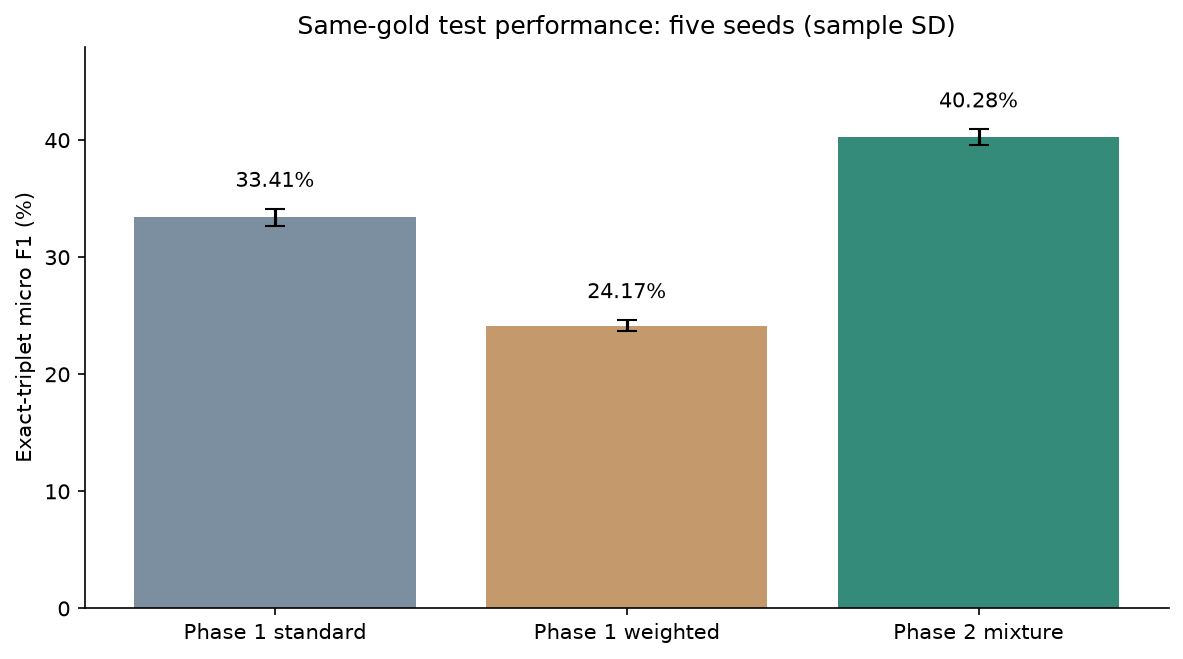

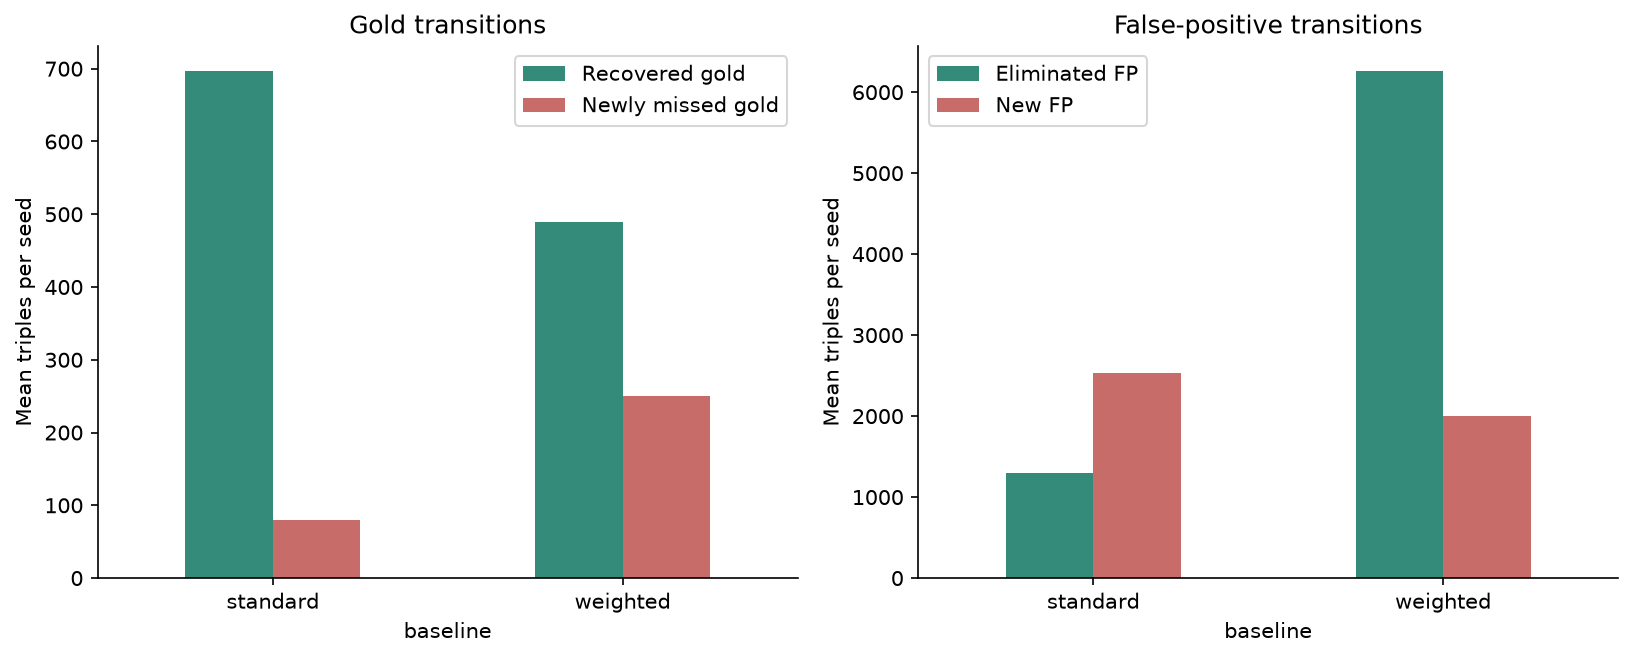

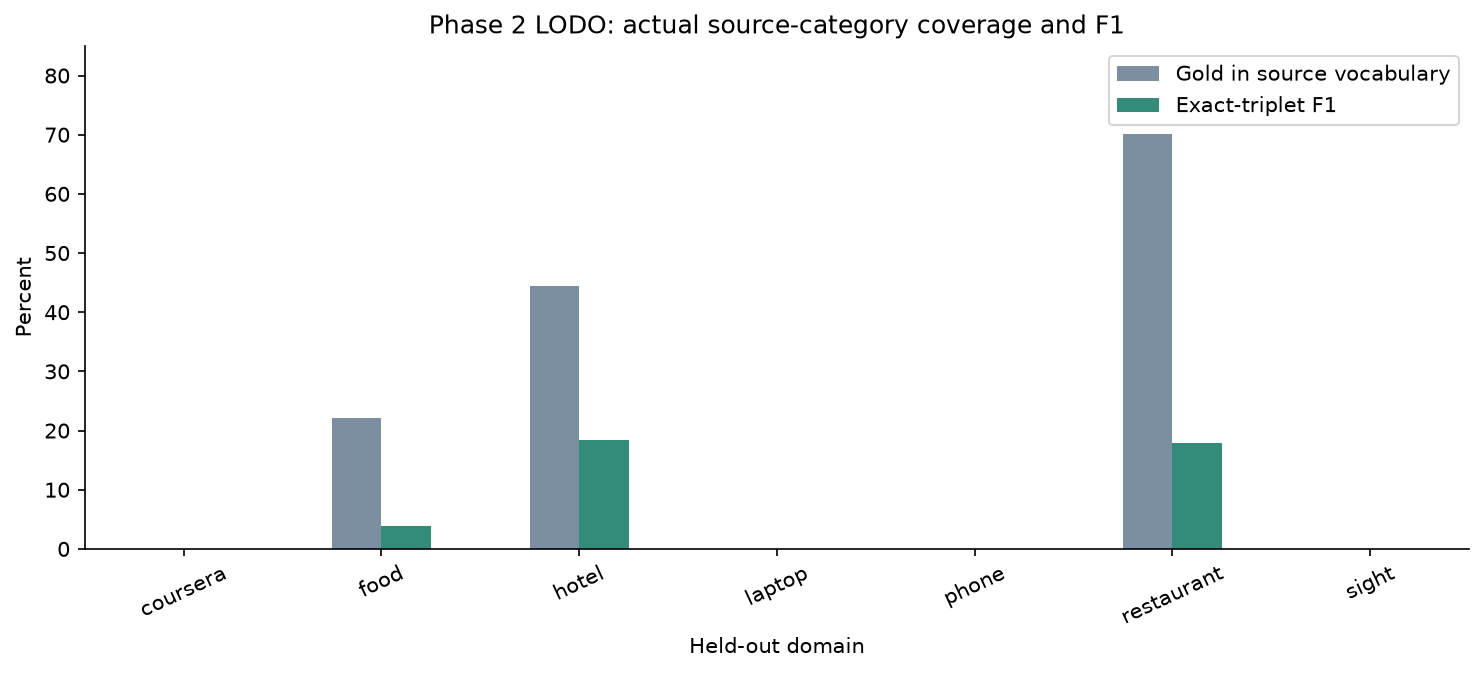

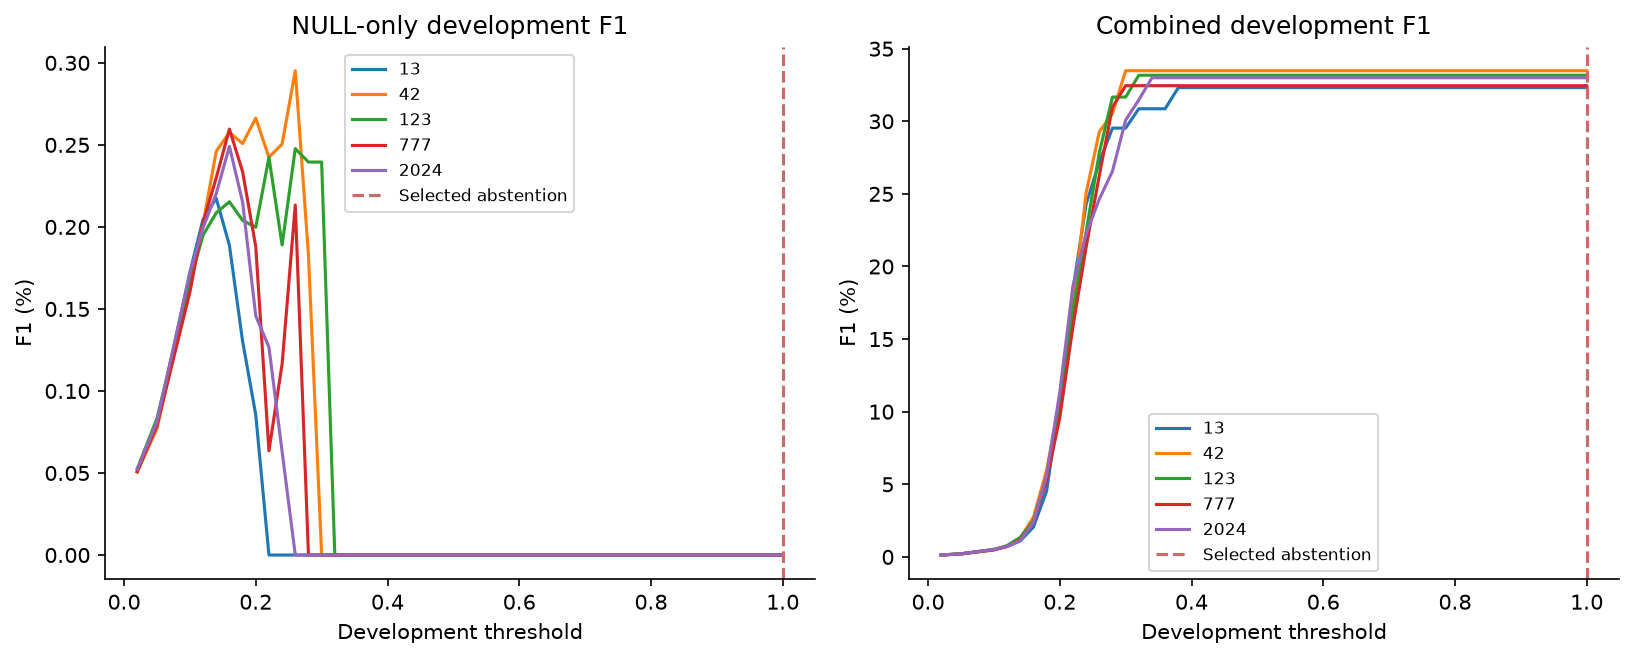

In [9]:
study.show_figures()

## 10. Export and conclusions

Export tables, figures and verification to `phase2/comparison/notebook/`.
Only generated analysis is replaced; frozen input evidence is preserved.

Explicit recovery improved. Term boundaries remain the largest measured missed
group; source-category coverage constrains LODO exact matching; the newer NULL
head did not demonstrate joint recovery improvement.

Historical test exposure makes the study exploratory. Future work should use
matched ablations, improve spans/category schemas and investigate NULL-specific
development selection before evaluating a fresh cohort.

The team reports equal shared contribution. External data/BERT/loss techniques
are attributed in [contribution documentation](../REPRODUCIBILITY_AND_CONTRIBUTIONS.md)
and the presentation bibliography. This revision preserves the team's analysis
with AI-assisted refactoring and documented corrections.

In [10]:
report_folder = study.export()
print("Analysis saved to:", report_folder)

Analysis saved to: D:\UoA\bertfinetune\phase2\comparison\notebook
